In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
df.isna().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Genre"] = le.fit_transform(df["Genre"])
df = df.drop("CustomerID", axis=1)

df.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


In [13]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
import scipy.cluster.hierarchy as sch

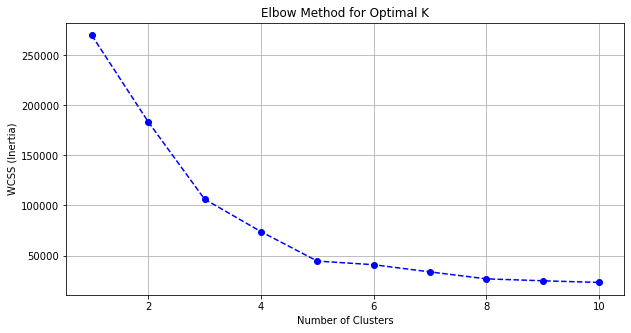

In [14]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

In [15]:
cluster_count = 5
kmeans = KMeans(n_clusters=cluster_count, random_state=42, n_init=10)
pred = kmeans.fit_predict(X)

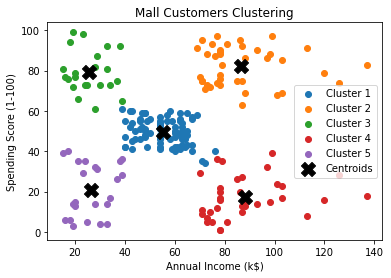

In [16]:
for i in range(cluster_count):
    plt.scatter(
        X[pred == i, 0],
        X[pred == i, 1],
        label=f'Cluster {i + 1}'
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Mall Customers Clustering')
plt.legend()
plt.show()

In [17]:
income = float(input("Enter Annual Income (k$): "))
score = float(input("Enter Spending Score (1-100): "))

user_input = [[income, score]]
prediction = kmeans.predict(user_input)[0]

print("Prediction: Cluster", prediction + 1)

Enter Annual Income (k$): 35
Enter Spending Score (1-100): 30
Prediction: Cluster 5


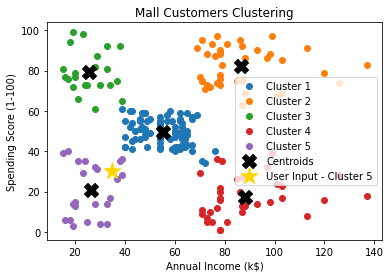

In [18]:
for i in range(cluster_count):
    plt.scatter(
        X[pred == i, 0],
        X[pred == i, 1],
        label=f'Cluster {i + 1}'
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Centroids'
)

plt.scatter(
    income, score,
    color='gold',
    marker='*',
    s=300,
    label=f'User Input - Cluster {prediction + 1}'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Mall Customers Clustering')
plt.legend()
plt.show()

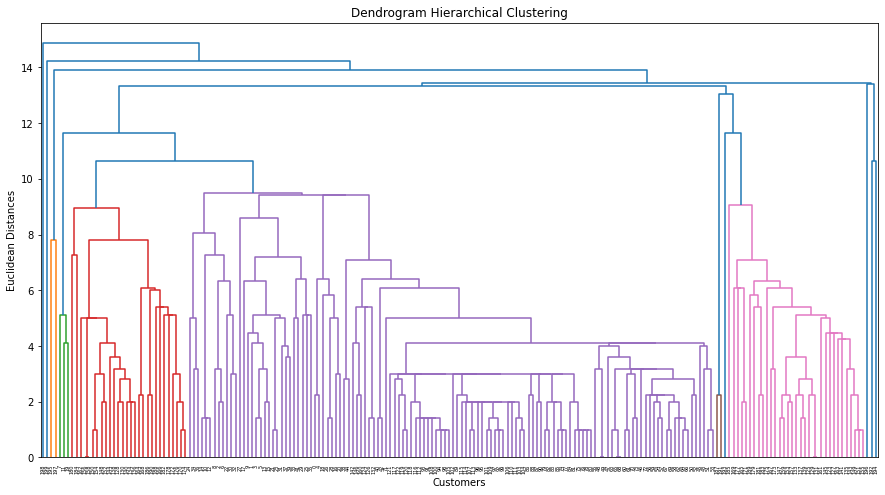

In [23]:
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='single')
y_hc = hc.fit_predict(X)

plt.figure(figsize=(15, 8))

dendrogram = sch.dendrogram(sch.linkage(X, method='single'))

plt.title('Dendrogram Hierarchical Clustering')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()